# Customer Segmentation Analysis Using K-Means Clustering

## Objective

The objective of this project is to segment customers based on their purchasing behaviour using the RFM framework and the K-Means clustering algorithm.

## Tools and Technologies

- Python
- pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## Project Workflow

1. Load and inspect the dataset.
2. Clean the transaction data.
3. Perform descriptive statistical analysis.
4. Calculate Recency, Frequency, and Monetary features.
5. Standardize the features.
6. Find a suitable number of clusters.
7. Apply K-Means clustering.
8. Visualize and profile customer segments.
9. Recommend marketing strategies.
10. Save the results.

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

print("All required libraries imported successfully!")

All required libraries imported successfully!


## 1. Dataset Loading

The Online Retail dataset contains transaction-level information about purchases. We load the CSV file into a pandas DataFrame so that we can inspect and prepare it for analysis.

In [14]:
file_path = r"C:\users\hi\Documents\OIBSIP\Customer-Segmentation-Analysis\data\online_retail.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "CSV file not found. Check the path and filename:\n" + file_path
    )

df = pd.read_csv(
    file_path,
    encoding="ISO-8859-1",
    sep=None,
    engine="python"
)

df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)

Column names:
['ï»¿InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,ï»¿InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 2. Initial Data Inspection

We inspect the dataset's dimensions, data types, missing values, duplicate records, and descriptive statistics. This helps us understand the quality and structure of the data before cleaning it.

In [19]:
print("Number of rows and columns:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Number of rows and columns: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB

Missing values in each column:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Number of duplicate rows: 5268

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Initial Data Inspection — Analysis

- The dataset shape shows the number of transaction records and columns.
- The data types help identify columns that require conversion.
- Missing values may affect customer-level analysis.
- Duplicate records may lead to inaccurate sales totals.
- Descriptive statistics summarize numerical fields such as quantity and unit price.

The next step is to clean the data before calculating customer metrics.

## 3. Data Cleaning

Data cleaning improves data quality before analysis. We remove duplicate records, exclude rows missing essential transaction details, remove cancelled invoices, and retain only transactions with valid positive quantities and unit prices.

In [20]:
required_columns = [
    "InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID"
]

missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}. "
        "Please check the CSV column names."
    )

clean_df = df.copy()

# Remove duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# Standardize data types
clean_df["InvoiceNo"] = clean_df["InvoiceNo"].astype("string").str.strip()

clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce",
    dayfirst=True
)

for col in ["Quantity", "UnitPrice", "CustomerID"]:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")

# Remove rows missing essential information
clean_df = clean_df.dropna(
    subset=["InvoiceNo", "InvoiceDate", "Quantity", "UnitPrice", "CustomerID"]
).copy()

# Remove blank invoice numbers
clean_df = clean_df[
    clean_df["InvoiceNo"].str.strip().ne("")
].copy()

# Exclude cancelled invoices, commonly identified by an invoice number starting with C
clean_df = clean_df[
    ~clean_df["InvoiceNo"].str.upper().str.startswith("C", na=False)
].copy()

# Keep valid positive purchases
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

# Convert customer IDs to integers after removing missing values
clean_df["CustomerID"] = clean_df["CustomerID"].astype("int64")

# Calculate total amount per transaction line
clean_df["TotalAmount"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# Remove invalid calculated values
clean_df = clean_df[
    np.isfinite(clean_df["TotalAmount"]) &
    (clean_df["TotalAmount"] > 0)
].copy()

clean_df = clean_df.reset_index(drop=True)

print("Data cleaning completed!")
print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Columns after cleaning:", clean_df.columns.tolist())

display(clean_df.head())

Data cleaning completed!
Rows before cleaning: 541909
Rows after cleaning: 166363
Columns after cleaning: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'TotalAmount']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-01-12 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-01-12 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-01-12 08:26:00,3.39,17850,United Kingdom,20.34


### Data Cleaning — Analysis

- Duplicate records were removed.
- Rows missing essential customer or transaction details were excluded.
- Cancelled invoices and transactions with non-positive quantities or prices were removed.
- The `TotalAmount` column was calculated using Quantity × UnitPrice.
- The cleaned dataset is now ready for exploratory analysis and customer segmentation.

The number of records removed depends on the original dataset's data quality.

## 4. Exploratory Data Analysis

Exploratory Data Analysis helps us understand sales patterns, customer activity, and purchasing behaviour. We calculate basic business metrics and examine sales by country and over time.

In [21]:
total_sales = clean_df["TotalAmount"].sum()
total_customers = clean_df["CustomerID"].nunique()
total_invoices = clean_df["InvoiceNo"].nunique()
total_items_sold = clean_df["Quantity"].sum()

invoice_summary = (
    clean_df.groupby(["CustomerID", "InvoiceNo"], as_index=False)
    .agg(
        InvoiceDate=("InvoiceDate", "max"),
        InvoiceValue=("TotalAmount", "sum")
    )
)

average_invoice_value = invoice_summary["InvoiceValue"].mean()

print(f"Total sales: £{total_sales:,.2f}")
print(f"Unique customers: {total_customers:,}")
print(f"Unique invoices: {total_invoices:,}")
print(f"Total items sold: {total_items_sold:,.0f}")
print(f"Average invoice value: £{average_invoice_value:,.2f}")

Total sales: £3,865,463.08
Unique customers: 2,997
Unique invoices: 7,961
Total items sold: 2,199,336
Average invoice value: £485.55


### Overall Business Metrics — Analysis

- **Total sales** represent the total value of valid transaction lines.
- **Unique customers** count the distinct customer IDs.
- **Unique invoices** count distinct invoice numbers.
- **Total items sold** is the sum of the quantities purchased.
- **Average invoice value** is the mean total value of an invoice, rather than the mean value of an individual item.

These metrics provide a high-level overview of the cleaned retail dataset.

### Sales by Country

This chart compares sales across countries and identifies the countries contributing the most revenue.

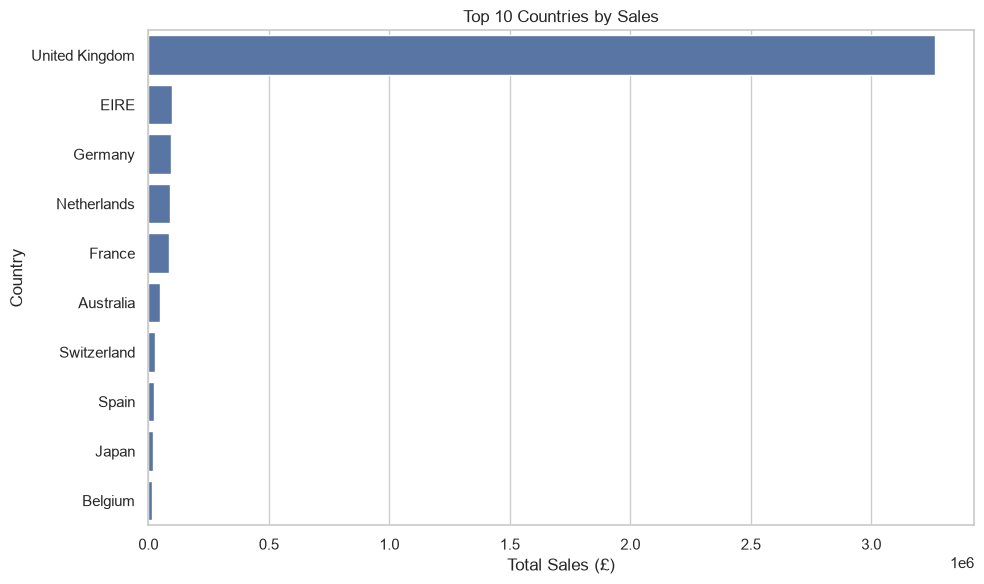

,Country,TotalAmount
0,United Kingdom,3263199.25
1,EIRE,97282.79
2,Germany,93933.59
3,Netherlands,89850.96
4,France,85054.61
5,Australia,49209.71
6,Switzerland,27692.51
7,Spain,24993.20
8,Japan,17134.16
9,Belgium,16942.55


In [22]:
country_sales = (
    clean_df.groupby("Country")["TotalAmount"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=country_sales,
    x="TotalAmount",
    y="Country"
)

plt.title("Top 10 Countries by Sales")
plt.xlabel("Total Sales (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(country_sales)

### Country Sales — Analysis

The chart ranks the top 10 countries by total sales. The highest bar represents the largest sales contribution among the countries shown. Compare the values in the displayed table to identify the leading market and the difference between countries.

The chart shows sales totals, not profit or customer loyalty.

### Monthly Sales Trend

This chart shows how total sales change over time. It helps identify months with relatively high or low recorded sales.

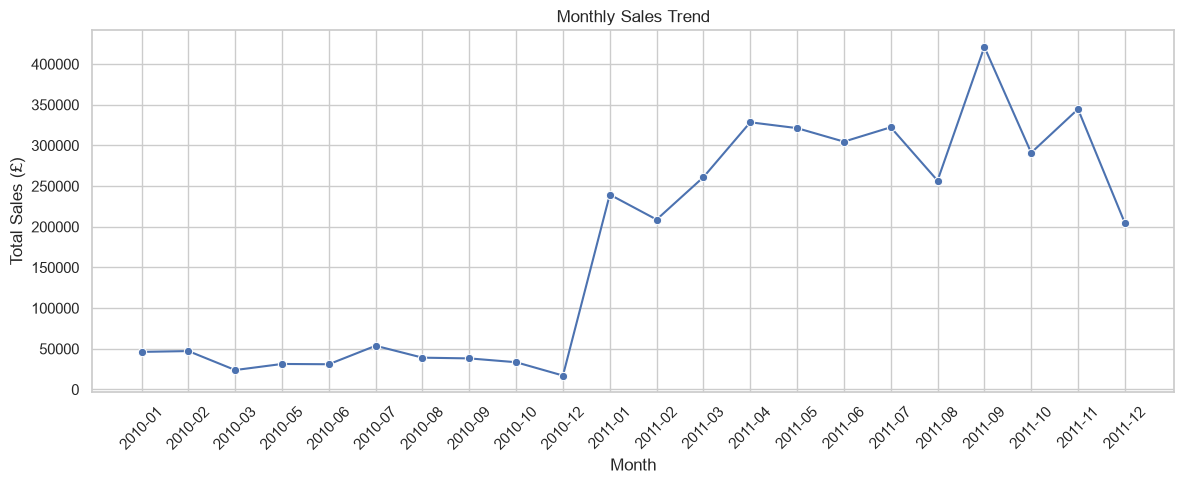

,Month,TotalAmount
0,2010-01,46192.49
1,2010-02,47197.57
2,2010-03,23876.63
3,2010-05,31361.28
4,2010-06,31009.33
5,2010-07,53730.96
6,2010-08,39094.20
7,2010-09,38193.91
8,2010-10,33488.38
9,2010-12,17102.35


In [23]:
monthly_sales = clean_df.copy()

monthly_sales["Month"] = (
    monthly_sales["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_sales = (
    monthly_sales.groupby("Month")["TotalAmount"]
    .sum()
    .reset_index()
    .sort_values("Month")
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="TotalAmount",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sales)

### Monthly Sales — Analysis

The line chart shows the direction of sales across the available months. Peaks indicate months with higher recorded sales, while dips indicate lower sales. These changes may reflect seasonality, promotions, or other factors, but the chart alone cannot establish the cause.

## 5. Customer Segmentation Using RFM

RFM stands for Recency, Frequency, and Monetary value. These features describe how recently a customer purchased, how often they purchased, and how much they spent.

- **Recency:** Days since the customer's latest purchase.
- **Frequency:** Number of distinct invoices per customer.
- **Monetary:** Total spending per customer in the available dataset.

We use these three behavioural features as input to the K-Means algorithm.

In [25]:
# Reference date: one day after the latest recorded transaction
reference_date = clean_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    clean_df.groupby("CustomerID")
    .agg(
        LastPurchaseDate=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalAmount", "sum")
    )
    .reset_index()
)

rfm["Recency"] = (
    reference_date - rfm["LastPurchaseDate"].dt.normalize()
).dt.days

# Keep only valid customer records
rfm = rfm.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["Recency", "Frequency", "Monetary"]
)

rfm = rfm[
    (rfm["Recency"] >= 0) &
    (rfm["Frequency"] > 0) &
    (rfm["Monetary"] > 0)
].copy()

rfm = rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary"]
].reset_index(drop=True)

print("RFM calculation completed!")
print("Number of customers:", len(rfm))
display(rfm.head())

print("\nRFM descriptive statistics:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe().T)

RFM calculation completed!
Number of customers: 2997


,CustomerID,Recency,Frequency,Monetary
0,12347,96,5,2540.29
1,12348,221,1,367.00
2,12350,312,1,334.40
3,12352,275,3,1296.38
4,12355,97,1,459.40



RFM descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,2997.0,155.419086,140.146976,1.0,40.00,125.00,219.00,698.0
Frequency,2997.0,2.656323,4.008919,1.0,1.00,2.00,3.00,106.0
Monetary,2997.0,1289.777471,5273.011876,5.9,244.41,466.29,1064.28,168469.6


### RFM Analysis — Interpretation

- Customers with lower Recency values purchased more recently.
- Customers with higher Frequency values placed more invoices.
- Customers with higher Monetary values spent more in total during the recorded period.

Monetary value is a measure of historical spending. It is not a prediction of future customer lifetime value (CLV). The available transaction history also limits what we can infer about long-term customer behaviour.

### RFM Feature Distributions

Histograms help us see how recency, purchase frequency, and spending vary across customers. These distributions can reveal whether a small group of customers has much higher purchase activity or spending than the rest.

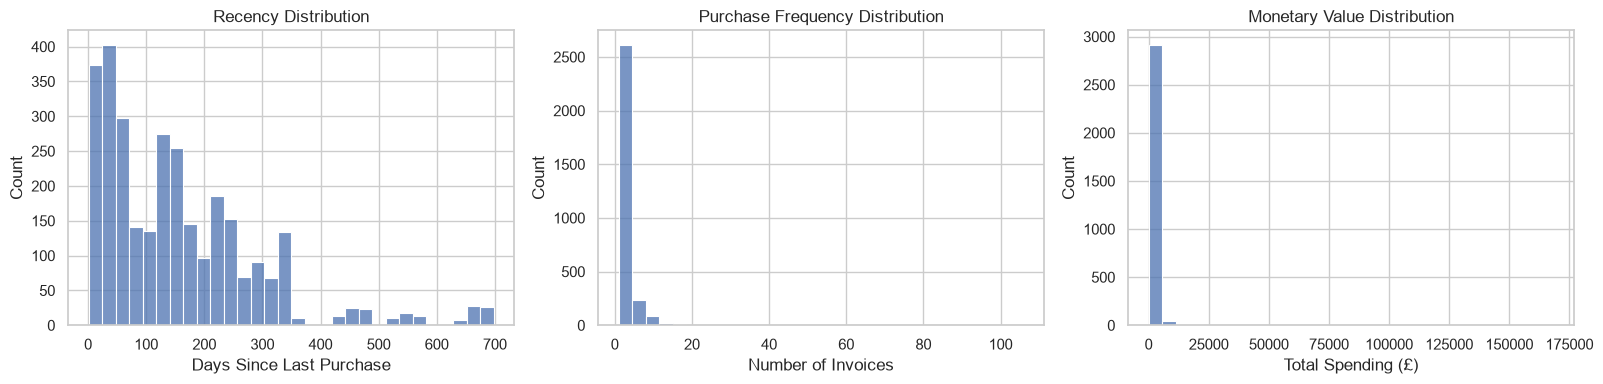

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(data=rfm, x="Recency", bins=30, ax=axes[0])
axes[0].set_title("Recency Distribution")
axes[0].set_xlabel("Days Since Last Purchase")

sns.histplot(data=rfm, x="Frequency", bins=30, ax=axes[1])
axes[1].set_title("Purchase Frequency Distribution")
axes[1].set_xlabel("Number of Invoices")

sns.histplot(data=rfm, x="Monetary", bins=30, ax=axes[2])
axes[2].set_title("Monetary Value Distribution")
axes[2].set_xlabel("Total Spending (£)")

plt.tight_layout()
plt.show()

### RFM Distribution — Analysis

Use the histograms to check whether the customer metrics are evenly distributed or skewed. If many customers have low frequency while a few have very high frequency, this suggests different levels of purchase activity. Similarly, unusually high monetary values may indicate a small group of high-spending customers.

These patterns help explain why feature scaling and clustering are useful.

## 6. Feature Scaling

The RFM features use different scales. We first apply a log transformation to reduce the effect of extreme positive values, then use StandardScaler to standardize each feature. This prevents a feature with a larger numerical scale from dominating distance calculations in K-Means.

In [27]:
features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce right-skewness
log_features = np.log1p(features)

# Standardize the transformed features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(log_features)

print("Feature scaling completed!")
print("Scaled data shape:", scaled_features.shape)
print("Features used:", features.columns.tolist())

Feature scaling completed!
Scaled data shape: (2997, 3)
Features used: ['Recency', 'Frequency', 'Monetary']


## 7. Elbow Method

The Elbow Method runs K-Means with different numbers of clusters and records the inertia for each model. Inertia measures the sum of squared distances between customers and their assigned cluster centres. We look for the point where improvements start to slow down.

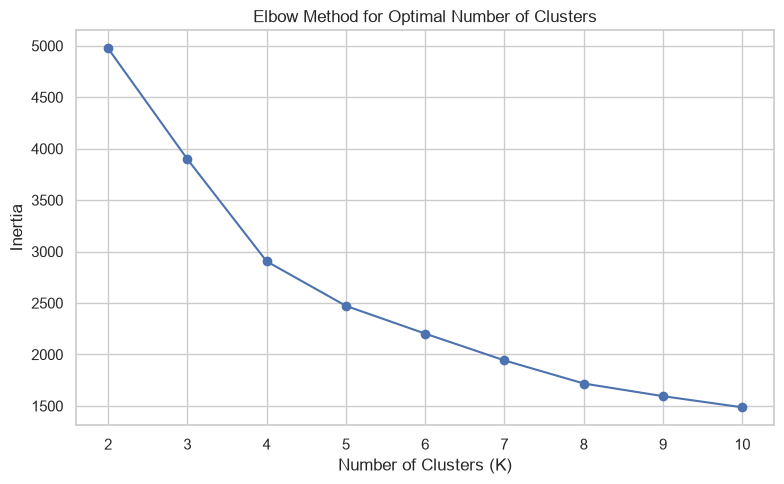

,K,Inertia
0,2,4974.421090
1,3,3898.358926
2,4,2905.172337
3,5,2472.647573
4,6,2202.744913
5,7,1942.337529
6,8,1718.082593
7,9,1594.992196
8,10,1486.596527


In [29]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(scaled_features)
    inertias.append(model.inertia_)

elbow_df = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias
})

plt.figure(figsize=(8, 5))
plt.plot(elbow_df["K"], elbow_df["Inertia"], marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

display(elbow_df)

### Elbow Method — Analysis

Inspect the curve and look for the point where the decrease in inertia begins to flatten. This is a candidate for the number of clusters. The elbow may not be sharply defined, so we will also compare silhouette scores before selecting the final value of K.

## 8. Silhouette Score Evaluation

The silhouette score measures how well each customer fits within their assigned cluster compared with other clusters. Scores closer to 1 generally indicate better separation, scores around 0 suggest overlapping clusters, and negative scores may indicate customers assigned to unsuitable clusters.

We compare scores for K values from 2 to 10 alongside the Elbow Method.

,K,Silhouette Score
0,2,0.438396
1,4,0.385183
2,3,0.344477
3,6,0.304849
4,8,0.304181
5,9,0.302155
6,10,0.301460
7,5,0.299131
8,7,0.297593


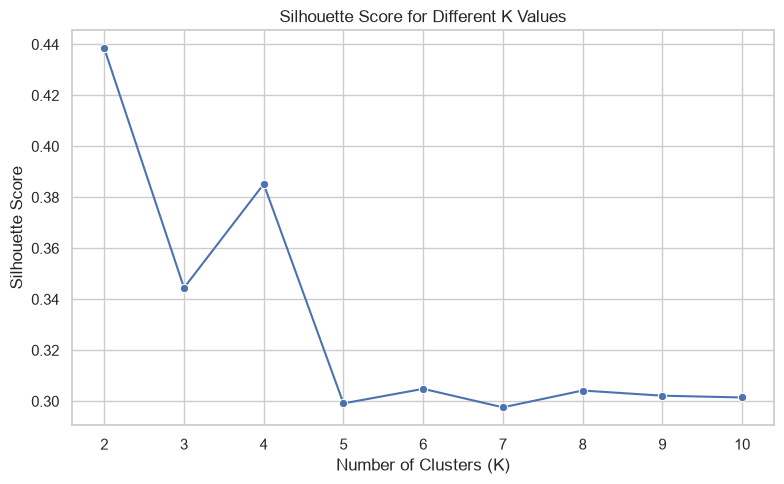

In [30]:
silhouette_results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(scaled_features)
    score = silhouette_score(scaled_features, labels)

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(
    silhouette_df.sort_values(
        "Silhouette Score",
        ascending=False
    ).reset_index(drop=True)
)

plt.figure(figsize=(8, 5))
sns.lineplot(
    data=silhouette_df,
    x="K",
    y="Silhouette Score",
    marker="o"
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(range(2, 11)))
plt.tight_layout()
plt.show()

### Silhouette Score — Analysis

Compare the silhouette scores to identify which K values produce better-separated clusters. Select a value that is supported by both the silhouette results and the Elbow Method. A high silhouette score is useful, but the segments should also be understandable and meaningful for business decisions.

## 9. K-Means Clustering

K-Means is an unsupervised machine learning algorithm that groups customers with similar feature patterns. We fit the algorithm using the standardized RFM features and assign a cluster number to each customer.

In [31]:
# Change this value after reviewing the Elbow Method and silhouette scores
selected_k = 4

if not 2 <= selected_k <= 10:
    raise ValueError("Please choose a K value between 2 and 10.")

kmeans = KMeans(
    n_clusters=selected_k,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(scaled_features)

print("K-Means clustering completed successfully!")
print("Number of clusters:", selected_k)

print("\nCustomer count in each cluster:")
display(
    rfm["Cluster"]
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .to_frame("CustomerCount")
)

display(rfm.head())

K-Means clustering completed successfully!
Number of clusters: 4

Customer count in each cluster:


,CustomerCount
Cluster,
0,255
1,277
2,968
3,1497


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12347,96,5,2540.29,2
1,12348,221,1,367.00,3
2,12350,312,1,334.40,3
3,12352,275,3,1296.38,2
4,12355,97,1,459.40,3


### K-Means — Analysis

Each customer has now been assigned to a cluster based on their Recency, Frequency, and Monetary values. Customers within the same cluster have similar patterns in the transformed and standardized feature space. Cluster numbers are identifiers only; they do not indicate a ranking.

## 10. Customer Cluster Visualization

We use scatter plots to visualize the assigned clusters using different combinations of the original RFM features. The charts help us interpret the differences between customer groups.

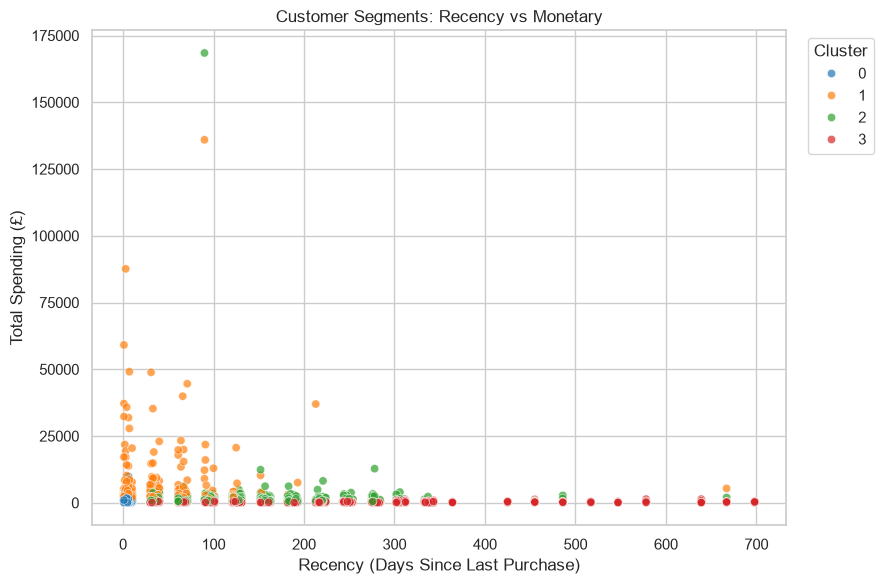

In [32]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Total Spending (£)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Recency vs Monetary — Analysis

This chart compares how recently customers purchased with how much they spent. Customers with low Recency and high Monetary values are recent, high-spending customers. Customers with high Recency may not have purchased recently, so their spending history should be considered when designing re-engagement campaigns.

Describe the actual cluster patterns shown in your graph.

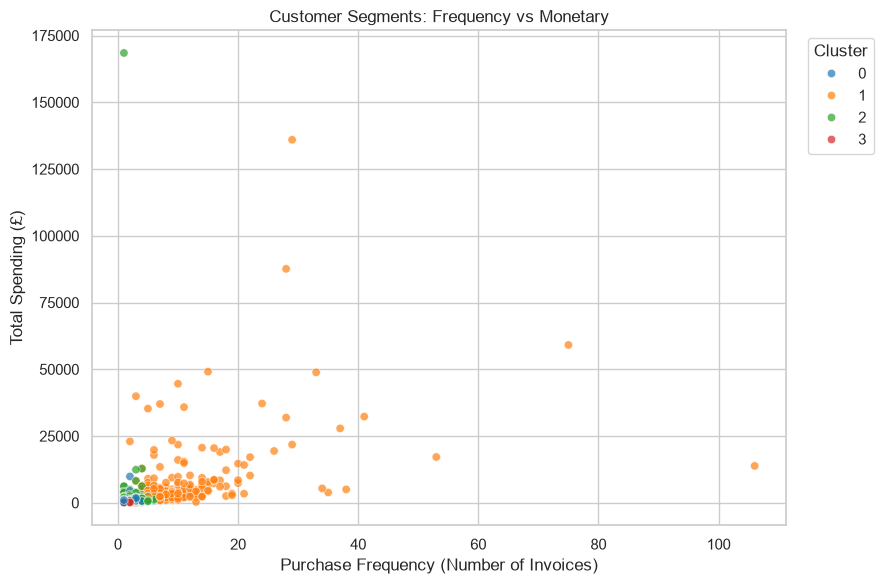

In [33]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Purchase Frequency (Number of Invoices)")
plt.ylabel("Total Spending (£)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Frequency vs Monetary — Analysis

This chart shows the relationship between purchase frequency and total spending. Customers with both high Frequency and high Monetary values are frequent, high-spending buyers. Customers with lower values on both axes have less recorded purchasing activity.

The chart shows association, not proof that more purchases cause higher spending.

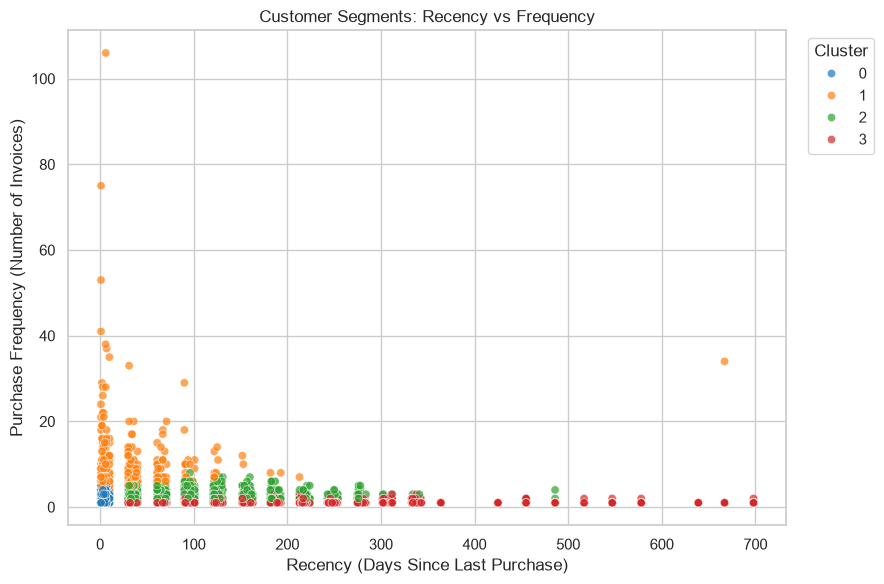

In [34]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette="tab10",
    alpha=0.7
)

plt.title("Customer Segments: Recency vs Frequency")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Purchase Frequency (Number of Invoices)")
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Recency vs Frequency — Analysis

This chart compares the time since the latest purchase with the number of invoices. Customers with lower Recency and higher Frequency have recently purchased repeatedly. Customers with higher Recency and lower Frequency may be suitable for re-engagement campaigns, depending on their spending history.

## 11. Customer Segment Profiling

We calculate the customer count and average RFM values for each cluster. This allows us to compare the purchasing behaviour of each segment and form business interpretations from the observed data.

In [35]:
cluster_profile = (
    rfm.groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "count"),
        AverageRecency=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean"),
        AverageMonetary=("Monetary", "mean"),
        TotalMonetary=("Monetary", "sum")
    )
    .round(2)
    .reset_index()
)

display(cluster_profile)

,Cluster,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,TotalMonetary
0,0,255,4.18,2.29,823.89,210091.19
1,1,277,37.47,10.53,6939.33,1922193.21
2,2,968,119.88,2.85,1350.76,1307532.72
3,3,1497,225.99,1.13,284.33,425645.96


### Cluster Profile — Analysis

Use the profile table to compare:

- **Average Recency:** Lower values mean customers purchased more recently.
- **Average Frequency:** Higher values mean customers placed more invoices.
- **Average Monetary:** Higher values mean customers spent more on average.
- **Customer Count:** Shows how many customers belong to each cluster.
- **Total Monetary:** Shows the combined historical spending of customers in that cluster.

Use these metrics together rather than deciding a segment's value based on just one measure.

## 12. Customer Count by Cluster

This bar chart compares the number of customers assigned to each cluster. It helps identify the largest and smallest customer segments.

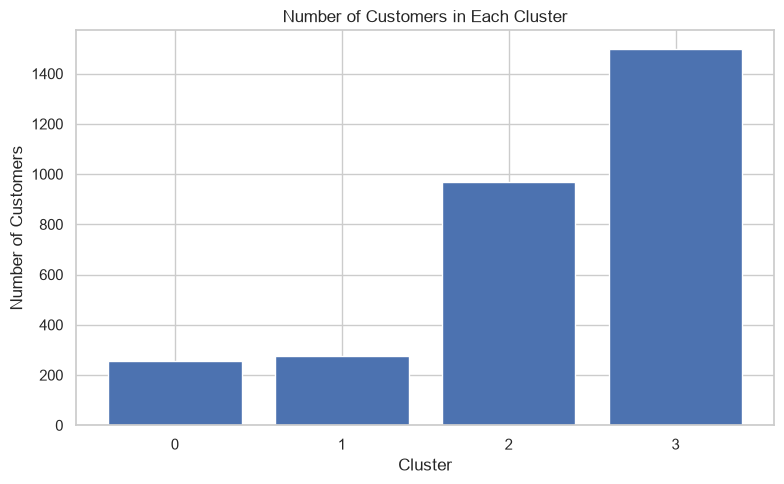

In [36]:
plt.figure(figsize=(8, 5))

plt.bar(
    cluster_profile["Cluster"].astype(str),
    cluster_profile["CustomerCount"]
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### Customer Count — Analysis

The tallest bar identifies the cluster with the most customers, and the shortest bar identifies the cluster with the fewest. The size of a cluster does not automatically indicate its profitability. Compare customer counts with average and total monetary values to understand the segments more fully.

## 13. Customer Segment Interpretation

K-Means generates numerical cluster labels, so we interpret each segment using its average RFM values. The following rule-based names are preliminary descriptions and should be checked against the cluster profile table.

In [37]:
# Overall customer medians used to interpret cluster profiles
median_recency = rfm["Recency"].median()
median_frequency = rfm["Frequency"].median()
median_monetary = rfm["Monetary"].median()

def describe_segment(row):
    recent = row["AverageRecency"] <= median_recency
    frequent = row["AverageFrequency"] >= median_frequency
    high_value = row["AverageMonetary"] >= median_monetary

    if recent and frequent and high_value:
        return "Loyal High-Value Customers"
    elif not recent and high_value:
        return "At-Risk Valuable Customers"
    elif recent and not frequent:
        return "Recent / Occasional Customers"
    elif not recent and not frequent:
        return "Low-Engagement Customers"
    else:
        return "Regular Customers"

cluster_profile["Segment"] = cluster_profile.apply(
    describe_segment,
    axis=1
)

display(cluster_profile)

,Cluster,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,TotalMonetary,Segment
0,0,255,4.18,2.29,823.89,210091.19,Loyal High-Value Customers
1,1,277,37.47,10.53,6939.33,1922193.21,Loyal High-Value Customers
2,2,968,119.88,2.85,1350.76,1307532.72,Loyal High-Value Customers
3,3,1497,225.99,1.13,284.33,425645.96,Low-Engagement Customers


### Customer Segment — Analysis

The segment names summarize the average behaviour of customers within each cluster. For example, a group with low average Recency, high Frequency, and high Monetary value can be interpreted as loyal, high-value customers.

These labels are based on comparisons with the overall customer medians. They are descriptive rules, not additional predictions made by K-Means.

## 14. Marketing Recommendations

Customer segmentation can help businesses tailor marketing campaigns to different purchasing patterns. Recommendations should reflect the segment profiles rather than assuming all customers need the same approach.

In [38]:
marketing_actions = {
    "Loyal High-Value Customers":
        "Reward loyalty with exclusive offers, early access, and personalized recommendations.",
    "At-Risk Valuable Customers":
        "Test win-back campaigns and relevant incentives to encourage another purchase.",
    "Recent / Occasional Customers":
        "Encourage repeat purchases with product recommendations and relevant follow-up offers.",
    "Low-Engagement Customers":
        "Test low-cost re-engagement campaigns and monitor customer responses.",
    "Regular Customers":
        "Use relevant product recommendations and offers to encourage repeat purchasing."
}

cluster_profile["MarketingAction"] = (
    cluster_profile["Segment"].map(marketing_actions)
)

print("Customer segments and recommended actions:")
display(
    cluster_profile[
        [
            "Cluster",
            "Segment",
            "CustomerCount",
            "AverageRecency",
            "AverageFrequency",
            "AverageMonetary",
            "MarketingAction"
        ]
    ]
)

Customer segments and recommended actions:


,Cluster,Segment,CustomerCount,AverageRecency,AverageFrequency,AverageMonetary,MarketingAction
0,0,Loyal High-Value Customers,255,4.18,2.29,823.89,"Reward loyalty with exclusive offers, early ac..."
1,1,Loyal High-Value Customers,277,37.47,10.53,6939.33,"Reward loyalty with exclusive offers, early ac..."
2,2,Loyal High-Value Customers,968,119.88,2.85,1350.76,"Reward loyalty with exclusive offers, early ac..."
3,3,Low-Engagement Customers,1497,225.99,1.13,284.33,Test low-cost re-engagement campaigns and moni...


### Marketing Recommendations — Analysis

- Reward customers who purchase recently, frequently, and spend more.
- Consider win-back campaigns for valuable customers who have not purchased recently.
- Encourage repeat purchases from recent but occasional customers.
- Test inexpensive campaigns for customers with low engagement.
- Measure campaign results before assuming that a recommendation will improve sales.

The effectiveness of these recommendations would need to be tested using actual campaign results.

## 15. Exporting Results

We export the customer-level RFM data and cluster profiles as CSV files. These files can be used for further analysis, reporting, or visualization in tools such as Excel and Power BI.

In [39]:
project_dir = r"C:\Users\hi\Documents\OIBSIP\Customer-Segmentation-Analysis"
data_dir = os.path.join(project_dir, "data")

os.makedirs(data_dir, exist_ok=True)

customer_output = os.path.join(
    data_dir, "customer_segments_results.csv"
)

profile_output = os.path.join(
    data_dir, "customer_cluster_profiles.csv"
)

rfm.to_csv(customer_output, index=False)
cluster_profile.to_csv(profile_output, index=False)

print("Results saved successfully!")
print("Customer-level results:", customer_output)
print("Cluster profile results:", profile_output)

print("\nFinal validation:")
print("Number of customers in RFM:", len(rfm))
print("Number of clusters:", rfm["Cluster"].nunique())
print("Missing values in RFM:")
display(rfm.isnull().sum().to_frame("Missing Values"))

Results saved successfully!
Customer-level results: C:\Users\hi\Documents\OIBSIP\Customer-Segmentation-Analysis\data\customer_segments_results.csv
Cluster profile results: C:\Users\hi\Documents\OIBSIP\Customer-Segmentation-Analysis\data\customer_cluster_profiles.csv

Final validation:
Number of customers in RFM: 2997
Number of clusters: 4
Missing values in RFM:


,Missing Values
CustomerID,0
Recency,0
Frequency,0
Monetary,0
Cluster,0


# Conclusion

Customer segmentation was performed using the RFM framework and the K-Means clustering algorithm on the Online Retail transaction dataset.

The data was inspected and cleaned to remove duplicate records, missing essential values, cancelled invoices, and invalid purchases. Recency, Frequency, and Monetary features were calculated for each customer. The features were log-transformed and standardized before clustering.

The Elbow Method and silhouette scores were used to evaluate possible cluster counts. Scatter plots were created to visualize the resulting customer groups, and cluster profiles were compared using average RFM values and customer counts.

The analysis produced **[number of clusters] customer segments**. The largest segment contained **[customer count] customers**. Based on the observed purchasing patterns, the business can test targeted strategies such as loyalty rewards, repeat-purchase offers, and re-engagement campaigns.

This project demonstrates how Python, data cleaning, exploratory analysis, data visualization, and unsupervised machine learning can support customer relationship management and data-driven marketing decisions.

In [ ]:
=